Traitement des images avec ouverture surfacique pour obtenir les zones incertaines sur lesquelles on ne veut pas s'entraîner

In [67]:
from PIL import Image
import torch
import torch.nn.functional as F
from torchvision import transforms
import matplotlib.pyplot as plt
from skimage import morphology as morph

In [68]:
device = "cpu"

In [69]:
PIL_to_tensor = transforms.ToTensor()

In [70]:
img = Image.open("../data/dataset/test/EMSR207/AOI01/EMSR207_AOI01_02/EMSR207_AOI01_02_GRA.png")
img_tensor = PIL_to_tensor(img)
img_tensor = img_tensor.view(1, *img_tensor.shape)

In [71]:
print(img_tensor.shape)  # Affiche la forme du tenseur

torch.Size([1, 3, 1442, 1973])


In [76]:
def imgs_to_niveaucouleur(imgs):
    # imgs de shape (3, H, W)

    imgs = imgs.unsqueeze(0)   # pour rajouter la dimension B quand on appelle depuis le loader et pas dans la boucle d'entraînement

    imgs = (imgs * 255).byte()
    imgs = imgs.permute(1, 0, 2, 3)   # (B, C, H, W) -> (C, B, H, W)

    colors = [[181, 254, 142], [254, 217, 142], [254, 153, 41], [204, 76, 2]]

    masks = []
    for c in colors:
        color_tensor = torch.tensor(c, dtype=imgs.dtype, device=imgs.device).view(-1, 1, 1, 1)
        mask = (imgs == color_tensor).all(dim=0)
        masks.append(mask)

    # # Combiner tous les masks
    # combined_mask = masks[0].clone()
    # for m in masks[1:]:
    #     combined_mask |= m  # ou “torch.logical_or(combined_mask, m)”

    # # Vérifier les pixels qui ne correspondent à aucune couleur
    # unknown_pixels = ~combined_mask
    # n_unknown = unknown_pixels.sum().item()

    # print(f"Nombre de pixels inconnus : {n_unknown}")


    # appliquer un filtrage (ouverture puis fermeture (voir morphologie mathématique))
    filtered_from_masks = []
    for mask in masks:
        filtered_mask = morph.area_opening(mask.squeeze(0).cpu().numpy(), area_threshold=32)
        filtered_mask = torch.from_numpy(filtered_mask).to(imgs.device)
        difference_mask = (mask != filtered_mask).bool()
        filtered_from_masks.append(difference_mask)

    union_maps = torch.zeros_like(masks[0], dtype=torch.bool, device=imgs.device)
    for m in filtered_from_masks:
        union_maps |= m

    masks.append(union_maps)


    out = torch.zeros((imgs.shape[1], imgs.shape[2], imgs.shape[3]), dtype=torch.int64, device=imgs.device)
    for i, mask in enumerate(masks):
        out[mask] = i + 1
        

    out = out.squeeze(0)  # (1, H, W) -> (H, W)

    return out

In [77]:
seed = 42
torch.manual_seed(seed)

# crop = transforms.RandomCrop(size=(1442, 1973))
crop = transforms.RandomCrop(size=(64, 64))

tensor = crop(img_tensor)[0]
print(tensor.shape)

tensor = imgs_to_niveaucouleur(tensor)
print(tensor.shape)

torch.Size([3, 64, 64])
torch.Size([64, 64])


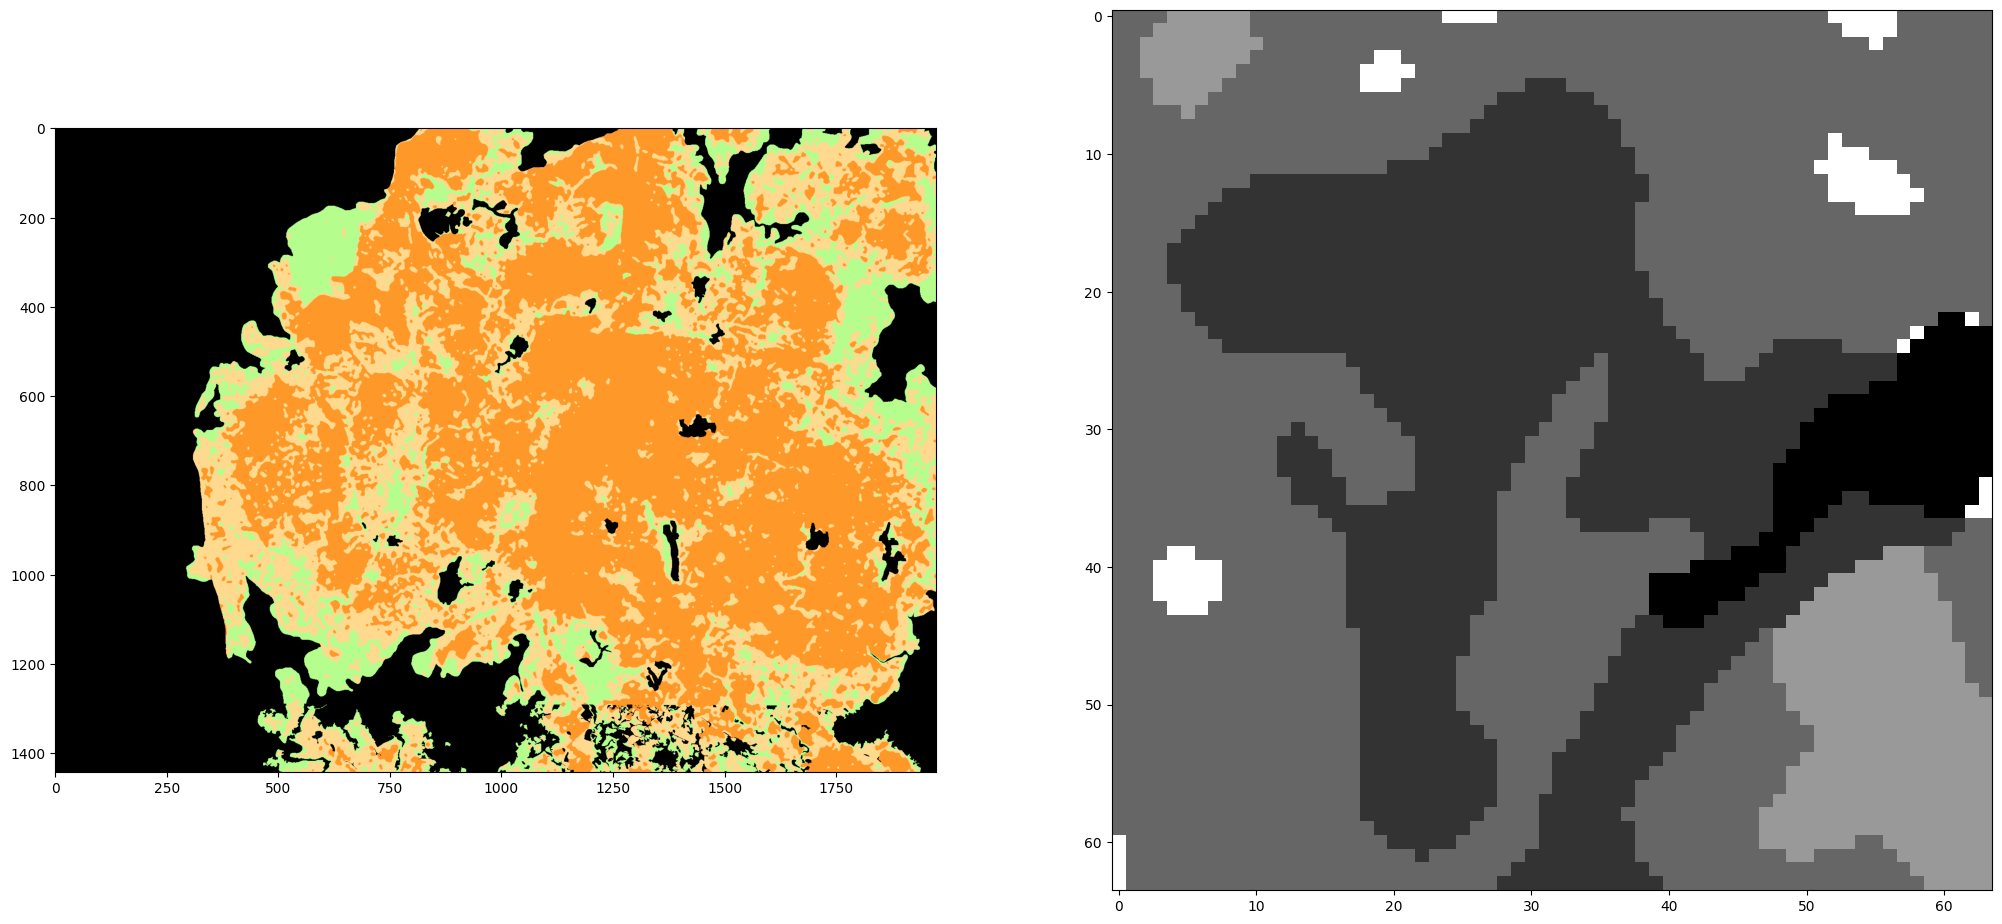

In [78]:
plt.figure(figsize=(25, 20))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.subplot(1, 2, 2)
plt.imshow(tensor.cpu().detach().numpy(), cmap='gray')
plt.show()

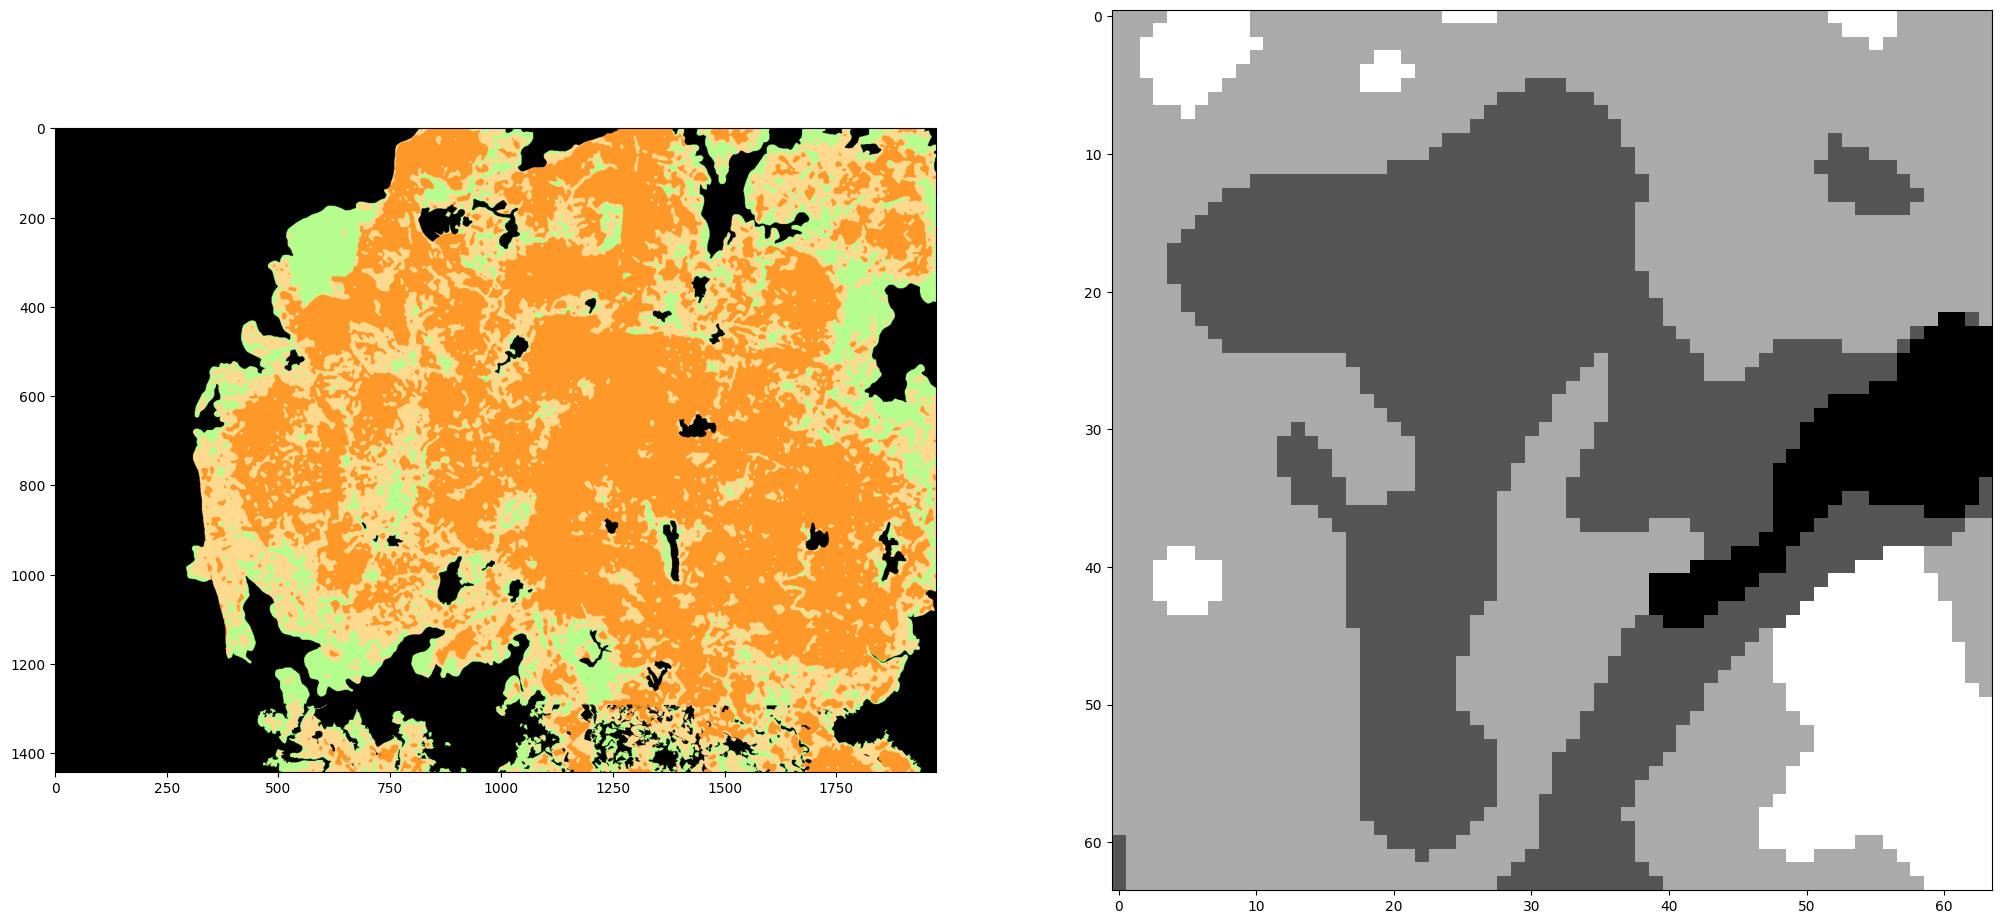

In [49]:
plt.figure(figsize=(25, 20))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.subplot(1, 2, 2)
plt.imshow(tensor.cpu().detach().numpy(), cmap='gray')
plt.show()

In [37]:
# seed = 42

# crop = transforms.RandomCrop(size=(64, 64))

# torch.manual_seed(seed)
# img_crop = crop(img)
# torch.manual_seed(seed)
# tensor_crop = crop(tensor)

# # tensor_crop = mode_filter(tensor_crop.unsqueeze(0), kernel_size=1).squeeze(0)

# plt.figure(figsize=(25, 20))
# plt.subplot(1, 2, 1)
# plt.imshow(img_crop)
# plt.subplot(1, 2, 2)
# plt.imshow(tensor_crop.cpu().detach().numpy(), cmap='gray')
# plt.show()